# EMQA_L1_negative_solar

**Romanian negative-price hours by month, and solar generation by year**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_negative_solar/EMQA_L1_negative_solar.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Romanian negative-price hours by month and year since 2023 (hour-equivalents) and metered Romanian solar generation per full year since 2018: negative hours cluster in spring as solar grows.

**Data:** Jan 2023 to 2026-10-31 (left); 2018-2025 (right). **Source:** energy-charts.info (Fraunhofer ISE); prices from the exchanges OPCOM (RO), IBEX (BG), HUPX (HU), EPEX SPOT (DE-LU), via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# native-resolution day-ahead prices (60-min until Sep 2025, 15-min from 1 Oct 2025), CET/CEST clock
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
X.index = X.index.tz_convert('Europe/Brussels')
X = X.loc[:str(END.date())]
# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]

data cut-off: 2026-10-31


## Computation

In [4]:
hrs = X['mtu_minutes'] / 60.0
hm = ((X['RO'] < 0) & X['RO'].notna()).mul(hrs).loc['2023-01-01':]
hm = hm.groupby([hm.index.year, hm.index.month]).sum().unstack(0)          # months x years, hours < 0
yr = GH.index.year
full_years = [y for y in sorted(set(yr)) if y < Y]
solar = GH['solar'].groupby(yr).sum() / 1e6                                # TWh over reported hours

def lfl_block(cols, y0, y1):
    """Jan..cut-off month of y1 vs the same months of y0, over the hours reported in BOTH years (TWh)."""
    s = GH[cols].sum(axis=1, min_count=len(cols))
    a = s[(s.index.year == y1) & (s.index.month <= END.month)]
    b_ = s[(s.index.year == y0) & (s.index.month <= END.month)]
    A = pd.Series(a.values, index=a.index.strftime('%m-%d %H'))
    B = pd.Series(b_.values, index=b_.index.strftime('%m-%d %H'))
    A, B = A[~A.index.duplicated()], B[~B.index.duplicated()]
    both = pd.concat([A.rename('a'), B.rename('b')], axis=1).dropna()
    return {'ytd': fl(both['a'].sum() / 1e6, 2), 'prev': fl(both['b'].sum() / 1e6, 2),
            'chg': fl((both['a'].sum() / both['b'].sum() - 1) * 100, 1), 'ytd_own': fl(A.sum() / 1e6, 2)}

show('neg.share_apr_may', 'share of negative hours in April-May, %', fl(hm.loc[[4, 5]].sum().sum() / hm.sum().sum() * 100, 1))
show('neg.share_jun_aug', 'share of negative hours in June-August, %', fl(hm.loc[[6, 7, 8]].sum().sum() / hm.sum().sum() * 100, 1))
for y in [2023, 2025]:
    show(f'neg.solar_twh.{y}', f'metered solar {y}, TWh', fl(solar.loc[y], 2))
show('mix.lfl.Solar.ytd_own', f'metered solar Jan-{MON_EN[END.month - 1]} {Y}, TWh', lfl_block(['solar'], Y - 1, Y)['ytd_own'])

share of negative hours in April-May, % = 49.6   [neg.share_apr_may]
share of negative hours in June-August, % = 34.0   [neg.share_jun_aug]
metered solar 2023, TWh = 1.46   [neg.solar_twh.2023]
metered solar 2025, TWh = 2.72   [neg.solar_twh.2025]
metered solar Jan-Oct 2026, TWh = 4.33   [mix.lfl.Solar.ytd_own]


## Chart

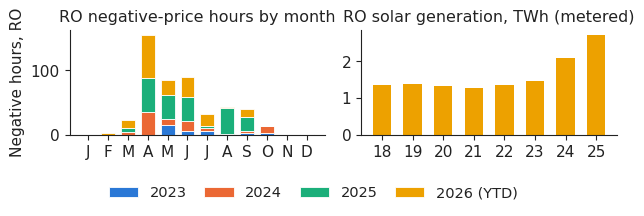

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.2))
bot = np.zeros(12)
for i, y in enumerate(hm.columns):
    v = hm[y].reindex(range(1, 13)).fillna(0.0).values                    # months after the cut-off have no bar
    axs[0].bar(range(1, 13), v, bottom=bot, color=SERIES[i], width=0.7, edgecolor='white', lw=0.6,
               label=f'{y}' + (' (YTD)' if y == Y else ''))
    bot += v
axs[0].set_xticks(range(1, 13))
axs[0].set_xticklabels(MON1)
axs[0].set_ylabel('Negative hours, RO')
axs[0].set_title('RO negative-price hours by month')
sy = [y for y in full_years if y >= 2018]
axs[1].bar(sy, [solar.loc[y] for y in sy], color=PAL['BG'], width=0.6)
axs[1].set_xticks(sy)
axs[1].set_xticklabels([str(y)[2:] for y in sy])
axs[1].set_title('RO solar generation, TWh (metered)')
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('negative_solar.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()